# Assignment: Decision Trees and Random Forests on Dry Bean Classification

## Objective

A food-processing system measures the shape of individual dry beans. Your task is to build a model that classifies each bean into one of seven varieties.

This is an experiment-driven assignment. You will change one modeling choice at a time, measure what changes, and explain why.

## Learning outcomes

By completing this assignment, you should be able to:

- recognize underfitting and overfitting in a Decision Tree;
- control tree complexity using depth and leaf-size parameters;
- compare Gini impurity, entropy, and log loss as split criteria;
- study how the number of trees affects a Random Forest;
- explain why random feature sampling creates diversity;
- interpret built-in Decision Tree and Random Forest feature importance;
- select a model using validation data and evaluate it once on unseen test data.

**Expected effort:** approximately 2-3 hours.


## Dataset

We will use the **UCI Dry Bean dataset**. Images of 13,611 bean grains were processed to produce 16 numerical shape measurements. The target contains seven registered bean varieties:

`SEKER`, `BARBUNYA`, `BOMBAY`, `CALI`, `DERMASON`, `HOROZ`, and `SIRA`.

Examples of input features include area, perimeter, major-axis length, eccentricity, roundness, compactness, and shape factors.

Dataset page: <https://archive.ics.uci.edu/dataset/602/dry+bean>

The loading code is provided. Your work begins with understanding the data and building the experiments.


## Assignment rules

1. Complete every `TODO` cell and remove its `NotImplementedError`.
2. Keep `RANDOM_STATE = 42` so results remain reproducible.
3. Use the **training set** to fit models.
4. Use the **validation set** to compare settings and select the final model.
5. Do not inspect test performance while tuning.
6. Evaluate the test set only once, after making the final model choice.
7. For every experiment, change only the parameter being studied.


## 1. Setup

Run the installation cell only if a package is missing.


In [1]:
# Run this only if required.
# %pip install numpy pandas matplotlib seaborn scikit-learn ucimlrepo


In [2]:
import sys
!{sys.executable} -m pip install ucimlrepo

In [3]:
import time
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay,
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)


## 2. Load the Dry Bean Dataset


In [4]:
# UCI dataset ID 602: Dry Bean
dry_bean = fetch_ucirepo(id=602)

X = dry_bean.data.features.copy()
y = dry_bean.data.targets["Class"].copy()

# Remove exact duplicate observations before splitting. Otherwise, identical
# rows could appear in both the training and evaluation sets.
data = pd.concat([X, y.rename("Class")], axis=1)
duplicate_count = data.duplicated().sum()
data = data.drop_duplicates().reset_index(drop=True)

X = data.drop(columns="Class")
y = data["Class"]

print("Exact duplicates removed:", duplicate_count)
print("Feature shape after cleaning:", X.shape)
print("Target shape after cleaning:", y.shape)
X.head()


Exact duplicates removed: 68
Feature shape after cleaning: (13543, 16)
Target shape after cleaning: (13543,)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166


In [5]:
# Basic checks supplied for you.
print("Missing feature values:", X.isna().sum().sum())
print("Duplicate observations remaining:", pd.concat([X, y], axis=1).duplicated().sum())
print("Target classes:", sorted(y.unique()))

Missing feature values: 0
Duplicate observations remaining: 0
Target classes: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']


## 3. Understand the Data

Before fitting a model, inspect the feature ranges and class distribution.

All inputs are numerical. Decision Trees and Random Forests compare feature thresholds, so scaling is not required for these models.

### TODO

- Display descriptive statistics for all features.
- Create a table containing the count and percentage of each bean class.
- Plot the class counts.


In [6]:
# TODO: Display descriptive statistics for the numerical features.

X.describe()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000,13543.000000
mean,53048.460385,854.993406,319.895602,202.365321,1.581075,0.750315,53767.986709,253.034094,0.749829,0.987152,0.873671,0.800352,0.006561,0.001719,0.644341,0.995078
std,29392.438324,214.722684,85.809260,45.051632,0.245245,0.091858,29844.248525,59.307709,0.048939,0.004650,0.059393,0.061464,0.001130,0.000595,0.098653,0.004347
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36282.500000,703.230000,253.086806,175.886357,1.430662,0.715144,36673.000000,214.933277,0.718735,0.985678,0.833410,0.763228,0.005893,0.001158,0.582517,0.993720
50%,44580.000000,793.896000,296.404589,192.491117,1.549860,0.763997,45122.000000,238.245711,0.759903,0.988288,0.883490,0.801514,0.006643,0.001700,0.642424,0.996393
75%,61382.000000,977.146500,376.312489,217.245403,1.703916,0.809671,62360.000000,279.560351,0.786849,0.990019,0.917031,0.834470,0.007270,0.002173,0.696341,0.997891
max,254616.000000,1985.370000,738.860154,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


          Count  Percentage
Class                      
DERMASON   3546       26.18
SIRA       2636       19.46
SEKER      2027       14.97
HOROZ      1860       13.73
CALI       1630       12.04
BARBUNYA   1322        9.76
BOMBAY      522        3.85


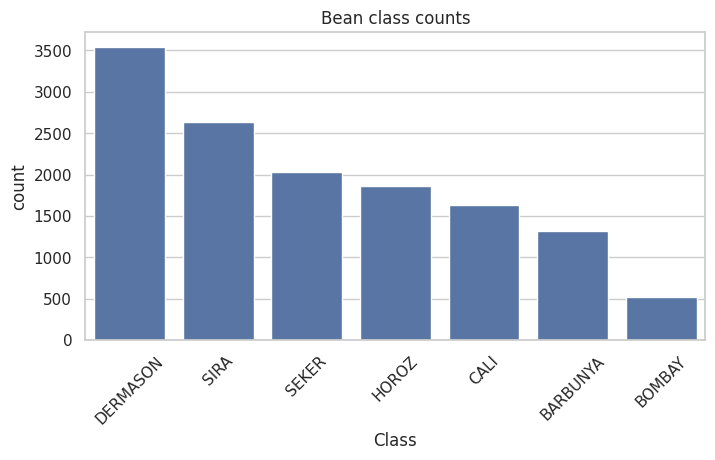

In [7]:
# TODO: Create a class-distribution table with Count and Percentage columns.
# TODO: Plot the number of observations in every class.

counts = y.value_counts()
class_dist = pd.DataFrame({
    "Count": counts,
    "Percentage": (counts / counts.sum() * 100).round(2)
})
print(class_dist)

plt.figure(figsize=(8,4))
sns.countplot(x=y, order=counts.index)
plt.title("Bean class counts")
plt.xticks(rotation=45)
plt.show()

### Question 1

1. Are all classes equally represented?
2. Why will **macro F1-score** be useful in addition to accuracy for this multiclass problem?

**Your answer:**

- **Ans 1** - No, the classes are imbalanced. BOMBAY and BARBUNYA have far fewer samples than DERMASON. Although SEKER, HOROZ, CALI samples have a closely balanced representation, compared to DERMASON and BOMBAY they are imbalanced.

- **Ans 2** - Macro F1 gives each class equal weight. It helps understand how well does the model do on every class, including the small ones. Accuracy just counts overall correct predictions out of all predictions. Using both together shows if the model is genuinely good across all 7 varieties, or just good at the common ones while missing smaller samples like BOMBAY.

## 4. Create Train, Validation, and Test Sets

Use a **60% training, 20% validation, and 20% test** split.

Apply stratification during both splitting steps so all seven classes retain similar proportions.

The validation set is used for experiments and model selection. The test set represents completely unseen data.


In [8]:
# TODO: First separate 20% of the full dataset as the test set.
# TODO: Then split the remaining 80% into 75% training and 25% validation.
# This produces an overall 60/20/20 split.
# Use stratification and RANDOM_STATE in both steps.

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.25, stratify=y_train_full, random_state=RANDOM_STATE
)

In [9]:
# TODO: Print the shape of all six objects.
# TODO: Verify the percentage distribution of classes in train, validation, and test targets.

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

for name, target in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"\n{name} class distribution (%):")
    print((target.value_counts(normalize=True) * 100).round(2))

Train: (8125, 16) (8125,)
Validation: (2709, 16) (2709,)
Test: (2709, 16) (2709,)

Train class distribution (%):
Class
DERMASON    26.18
SIRA        19.47
SEKER       14.97
HOROZ       13.74
CALI        12.04
BARBUNYA     9.76
BOMBAY       3.85
Name: proportion, dtype: float64

Validation class distribution (%):
Class
DERMASON    26.21
SIRA        19.45
SEKER       14.95
HOROZ       13.73
CALI        12.03
BARBUNYA     9.75
BOMBAY       3.88
Name: proportion, dtype: float64

Test class distribution (%):
Class
DERMASON    26.17
SIRA        19.45
SEKER       14.99
HOROZ       13.73
CALI        12.03
BARBUNYA     9.78
BOMBAY       3.84
Name: proportion, dtype: float64


### Question 2

Why should the test set remain untouched until the final model has been selected?

**Your answer:**

- The test set must simulate real unseen data. If I use/view it while tuning, I will unconsciously pick settings that fit the test set and the final score will no longer tell how the model performs on new data. The test set must be untouched until the final model is selected, so that it gives an honest performance result.

## 5. Evaluation Helpers

These helpers are provided so that your experiments use consistent metrics.


In [10]:
def classification_metrics(y_true, y_pred):
    # Return metrics suitable for multiclass model comparison.
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
    }


def fit_and_measure(model, X_train, y_train, X_eval, y_eval):
    # Fit a fresh model and return train/evaluation metrics plus training time.
    fitted_model = clone(model)
    start = time.perf_counter()
    fitted_model.fit(X_train, y_train)
    fit_seconds = time.perf_counter() - start

    train_pred = fitted_model.predict(X_train)
    eval_pred = fitted_model.predict(X_eval)

    return fitted_model, {
        "Train Accuracy": accuracy_score(y_train, train_pred),
        "Validation Accuracy": accuracy_score(y_eval, eval_pred),
        "Validation Macro F1": f1_score(y_eval, eval_pred, average="macro", zero_division=0),
        "Fit Time (s)": fit_seconds,
    }

## 6. Baseline Decision Tree

First train an unrestricted Decision Tree. This gives the tree enough freedom to keep splitting until its stopping rules are reached.

### Before running the model

Do you expect its training accuracy to be low or high? What do you expect on validation data?

**Your prediction:**

- Training accuracy should be very high. Validation accuracy will be lower.

In [11]:
# TODO: Create an unrestricted DecisionTreeClassifier using RANDOM_STATE.
# TODO: Fit it on the training set with fit_and_measure().
# TODO: display the returned metrics.

baseline_tree = DecisionTreeClassifier(random_state=RANDOM_STATE)
baseline_tree, baseline_metrics = fit_and_measure(baseline_tree, X_train, y_train, X_val, y_val)
baseline_metrics

{'Train Accuracy': 1.0,
 'Validation Accuracy': 0.8892580287929125,
 'Validation Macro F1': 0.9046058674357556,
 'Fit Time (s)': 0.31286073399996894}

Depth: 24
Leaves: 561


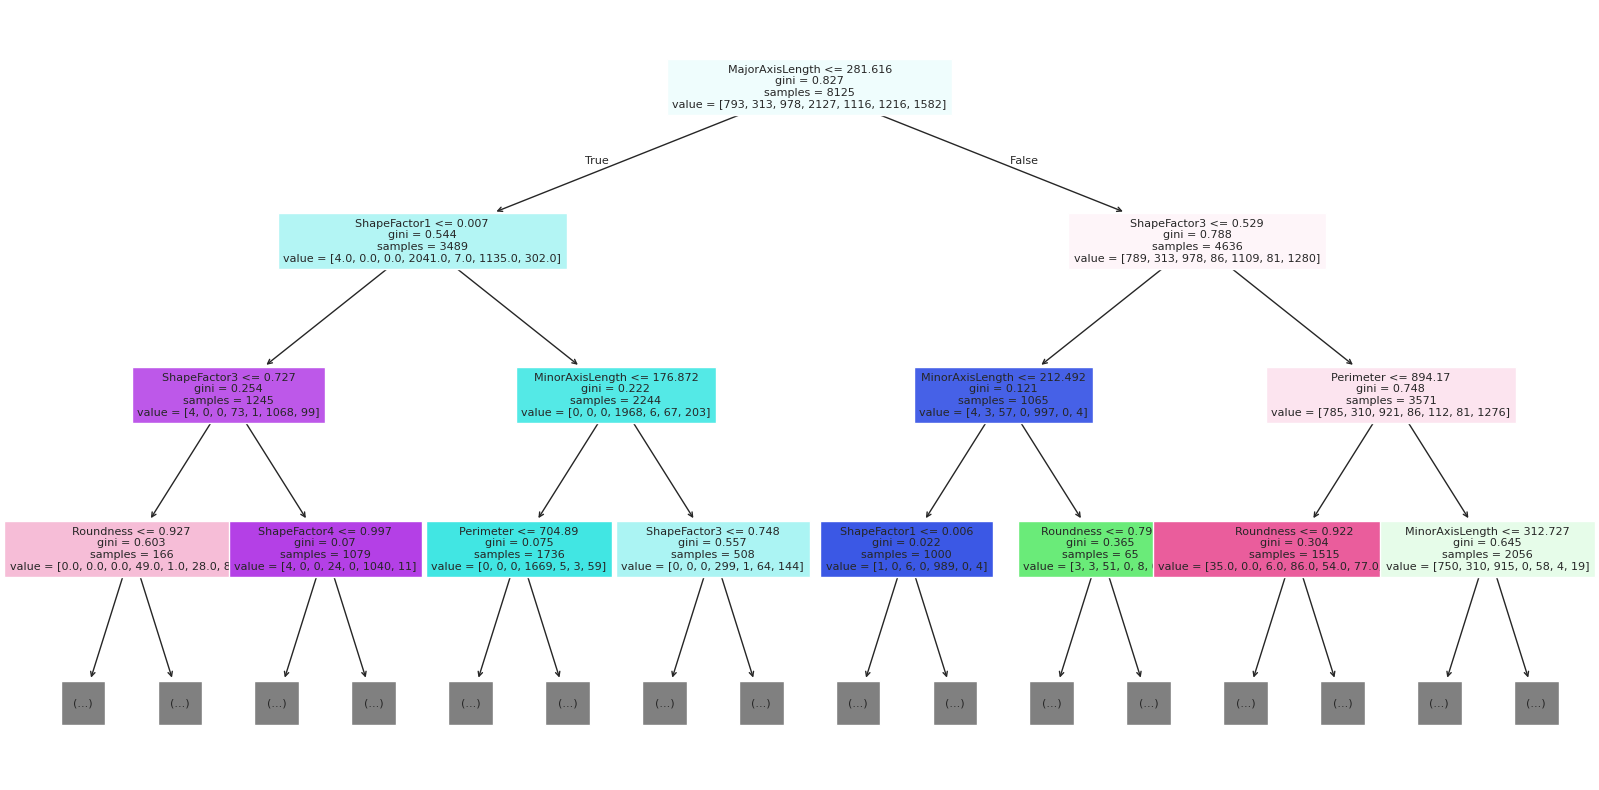

In [12]:
# TODO: Report the fitted tree's depth and number of leaves.
# TODO: Plot only the first three levels of the tree so the figure remains readable.

print("Depth:", baseline_tree.get_depth())
print("Leaves:", baseline_tree.get_n_leaves())

plt.figure(figsize=(20,10))
plot_tree(baseline_tree, max_depth=3, feature_names=X.columns, filled=True, fontsize=8)
plt.show()

### Question 3

Compare training and validation accuracy. What evidence of overfitting or underfitting do you observe?

**Your answer:**

- Training accuracy is 100% and validation accuracy is almost 89% (lower). This gap is a clear evidence of overfitting.

## 7. Experiment 1: Maximum Tree Depth

`max_depth` limits how many levels the tree can grow.

Test:

```python
[1, 2, 3, 5, 10, None]
```

Keep all other model settings unchanged.

### Before running the experiment

Sketch or describe how you expect training and validation accuracy to change as depth increases.


In [13]:
depth_values = [1, 2, 3, 5, 10, None]

# TODO: Train one Decision Tree for every max_depth value.
# TODO: Store max_depth, train accuracy, validation accuracy,
# validation macro F1, actual tree depth, and number of leaves.
# TODO: Convert the collected results into depth_results DataFrame.

rows = []
for depth in depth_values:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE)
    fitted, m = fit_and_measure(tree, X_train, y_train, X_val, y_val)
    rows.append({
        "max_depth": depth,
        "Train Accuracy": m["Train Accuracy"],
        "Validation Accuracy": m["Validation Accuracy"],
        "Validation Macro F1": m["Validation Macro F1"],
        "Actual Depth": fitted.get_depth(),
        "Leaves": fitted.get_n_leaves(),
    })
depth_results = pd.DataFrame(rows)
depth_results

,max_depth,Train Accuracy,Validation Accuracy,Validation Macro F1,Actual Depth,Leaves
0,1.0,0.408738,0.410114,0.163249,1,2
1,2.0,0.653415,0.653008,0.453493,2,4
2,3.0,0.776369,0.776301,0.597602,3,8
3,5.0,0.892554,0.883352,0.887071,5,32
4,10.0,0.969231,0.909930,0.923272,10,282
5,NaN,1.000000,0.889258,0.904606,24,561


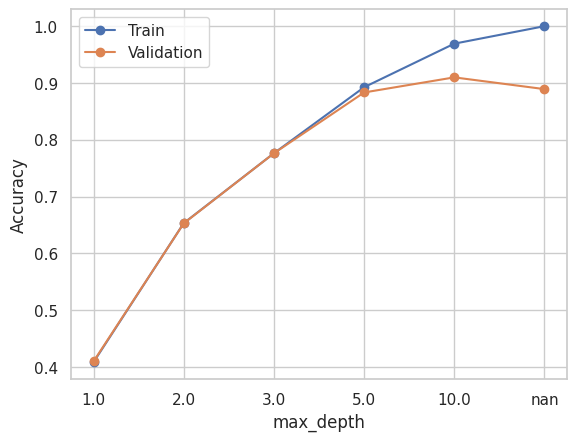

In [14]:
# TODO: Plot training accuracy and validation accuracy against max_depth.
# Represent None with a readable label such as "Unlimited".

labels = [str(d) if d is not None else "Unlimited" for d in depth_results["max_depth"]]
plt.plot(labels, depth_results["Train Accuracy"], marker="o", label="Train")
plt.plot(labels, depth_results["Validation Accuracy"], marker="o", label="Validation")
plt.xlabel("max_depth"); plt.ylabel("Accuracy"); plt.legend()
plt.show()

### Question 4

1. Which depth underfits?
2. Where does validation performance become strong?
3. At what point does additional depth mainly improve training performance?

**Your answer:**

- **Ans 1** - Depth 1-2 underfits (both train and validation accuracy low).
- **Ans 2** - Validation performance becomes strong around the depth where the two curves are close and high (depth 10).
- **Ans 3** - Past depth 10, train accuracy keeps climbing but validation accuracy drops - extra depth overfits.


## 8. Experiment 2: Minimum Samples per Leaf

`min_samples_leaf` controls the minimum number of training observations allowed in every leaf.

Test:

```python
[1, 2, 5, 10, 20, 50]
```

For this experiment, use the single `max_depth` value that performed best in Experiment 1. Keep it fixed for every run.

### Before running the experiment

How should increasing the minimum leaf size affect tree complexity?


In [15]:
leaf_values = [1, 2, 5, 10, 20, 50]
selected_depth = 10 # TODO: Replace using Experiment 1, not test results.

# TODO: Train and evaluate one tree for every min_samples_leaf value.
# TODO: Store train accuracy, validation accuracy, validation macro F1,
# actual depth, and number of leaves in leaf_results.

rows = []
for leaf in leaf_values:
    tree = DecisionTreeClassifier(max_depth=selected_depth, min_samples_leaf=leaf, random_state=RANDOM_STATE)
    fitted, m = fit_and_measure(tree, X_train, y_train, X_val, y_val)
    rows.append({
        "min_samples_leaf": leaf,
        "Train Accuracy": m["Train Accuracy"],
        "Validation Accuracy": m["Validation Accuracy"],
        "Validation Macro F1": m["Validation Macro F1"],
        "Actual Depth": fitted.get_depth(),
        "Leaves": fitted.get_n_leaves(),
    })
leaf_results = pd.DataFrame(rows)
leaf_results

,min_samples_leaf,Train Accuracy,Validation Accuracy,Validation Macro F1,Actual Depth,Leaves
0,1,0.969231,0.909930,0.923272,10,282
1,2,0.961846,0.909192,0.921110,10,262
2,5,0.951631,0.909561,0.922711,10,220
3,10,0.938585,0.910299,0.922542,10,159
4,20,0.928000,0.910668,0.920630,10,111
5,50,0.916062,0.907346,0.916185,10,57


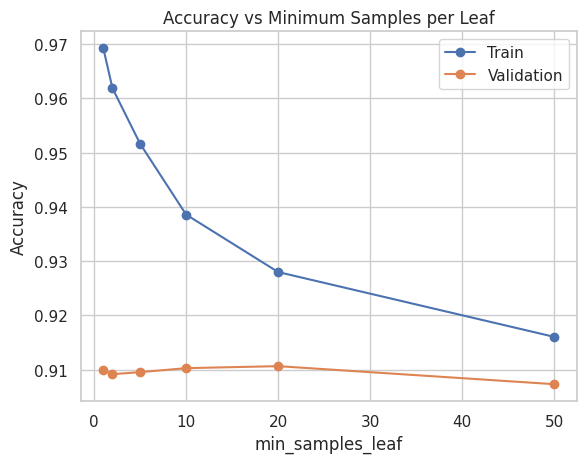

In [16]:
# TODO: Create a plot that compares train and validation accuracy
# across the tested minimum leaf sizes.

plt.plot(leaf_results["min_samples_leaf"], leaf_results["Train Accuracy"], marker="o", label="Train")
plt.plot(leaf_results["min_samples_leaf"], leaf_results["Validation Accuracy"], marker="o", label="Validation")
plt.xlabel("min_samples_leaf")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Minimum Samples per Leaf")
plt.legend()
plt.show()

### Question 5

1. How did larger leaves affect depth and the number of leaves?
2. Which setting produced the best validation result?
3. Did making leaves very large eventually cause underfitting?

**Your answer:**

- **Ans 1** - Larger the leaf size - fewer the leaves and shallower depth - the tree gets simpler.
- **Ans 2** - The middle values (e.g. 10-20) produced best validation result. 1 was too complex and 50 was too simple.
- **Ans 3** - Yes, very large leaf sizes (e.g. 50) reduce train accuracy and cause underfitting.

## 9. Experiment 3: Split Criterion

A tree needs a measure of node impurity to compare candidate splits. Compare:

```python
["gini", "entropy", "log_loss"]
```

Use your selected `max_depth` and `min_samples_leaf` values for all three models.

### Before running the experiment

Do you expect these criteria to produce identical trees? Do you expect a large or small performance difference?

- **Ans** - Trees will differ slightly (gini/entropy/log_loss compute impurity differently), but performance differences are usually small since all three measure similar things.


In [17]:
criteria = ["gini", "entropy", "log_loss"]
selected_leaf_size = 10  # TODO: Replace using Experiment 2.

# TODO: Train and evaluate one Decision Tree for each criterion.
# TODO: Store criterion, train accuracy, validation accuracy,
# validation macro F1, depth, leaves, and fit time in criterion_results.

rows = []
for crit in criteria:
    tree = DecisionTreeClassifier(max_depth=selected_depth, min_samples_leaf=selected_leaf_size,
                                   criterion=crit, random_state=RANDOM_STATE)
    fitted, m = fit_and_measure(tree, X_train, y_train, X_val, y_val)
    rows.append({
        "criterion": crit,
        "Train Accuracy": m["Train Accuracy"],
        "Validation Accuracy": m["Validation Accuracy"],
        "Validation Macro F1": m["Validation Macro F1"],
        "Depth": fitted.get_depth(),
        "Leaves": fitted.get_n_leaves(),
        "Fit Time (s)": m["Fit Time (s)"],
    })
criterion_results = pd.DataFrame(rows)
criterion_results

,criterion,Train Accuracy,Validation Accuracy,Validation Macro F1,Depth,Leaves,Fit Time (s)
0,gini,0.938585,0.910299,0.922542,10,159,0.224025
1,entropy,0.940677,0.911776,0.924686,10,176,0.300277
2,log_loss,0.940677,0.911776,0.924686,10,176,0.294032


### Question 6

1. Did all criteria produce the same depth and number of leaves?
2. Was one criterion clearly superior, or were the differences small?
3. Which criterion will you carry forward, and why?

**Your answer:**

- Ans 1 - No, not all three. entropy and log_loss produced identical trees - 176 leaves at depth 10. gini differed slightly, produced 159 leaves at the same depth of 10.
- Ans 2 - The differences are small/negligible. entropy/log_loss scored marginally higher - a gap of only 0.002. No criterion is clearly superior.
- Ans 3 - I will carry forward entropy because it is more commonly interpretable than log_loss.


## 10. Baseline Random Forest

A Random Forest combines many trees trained on bootstrap samples. At each split, each tree considers only a subset of features. The final prediction is obtained through voting.

Train a baseline forest with:

```python
n_estimators=100
oob_score=True
```

Keep the other parameters at their default values and use `n_jobs=-1`.


In [18]:
# TODO: Create and train the baseline Random Forest.
# TODO: Report train accuracy, validation accuracy, validation macro F1,
# OOB score, and fit time.

rf_baseline = RandomForestClassifier(n_estimators=100, oob_score=True, n_jobs=-1, random_state=RANDOM_STATE)
rf_baseline, rf_metrics = fit_and_measure(rf_baseline, X_train, y_train, X_val, y_val)
rf_metrics["OOB Score"] = rf_baseline.oob_score_
rf_metrics

{'Train Accuracy': 1.0,
 'Validation Accuracy': 0.9317091177556294,
 'Validation Macro F1': 0.9426208411645306,
 'Fit Time (s)': 3.404598551000049,
 'OOB Score': 0.9206153846153846}

### Question 7

How does the baseline Random Forest compare with the unrestricted Decision Tree in validation performance and overfitting gap?

**Your answer:**

- **Validation performance**: The Random Forest clearly does better - validation accuracy increases from ~89% to ~93% and validation macro F1 gets better from 0.9046 to 0.9426, showing strong performance across all 7 classes, not just the common ones.

- **Overfitting gap**: Training accuracy is 100% for both models. But the train-validation gap is much smaller for the forest (0.068) than for the single tree (0.11).

Random forest generalizes better, even though it overfits somewhat.

## 11. Experiment 4: Number of Trees

Test:

```python
[1, 5, 10, 25, 50, 100, 200]
```

For every forest, enable `oob_score=True` and keep the remaining settings unchanged.

> With only one or a few trees, some observations may receive no OOB predictions. A warning or an unstable OOB score is expected and is itself an important observation.

### Before running the experiment

Will adding more trees continuously produce large improvements, or should performance eventually stabilize?


- **Ans** - While adding more trees, performance will go up fast at the start (1 to 20 trees), and then it will be stable. After that, adding more trees will cost more time without big improvements.

In [19]:
tree_counts = [1, 5, 10, 25, 50, 100, 200]

# TODO: Train one Random Forest for every n_estimators value.
# TODO: Store train accuracy, validation accuracy, validation macro F1,
# OOB score, and fit time in n_trees_results.

rows = []
for n in tree_counts:
    rf = RandomForestClassifier(
        n_estimators=n,
        oob_score=True,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    )
    fitted, m = fit_and_measure(rf, X_train, y_train, X_val, y_val)
    rows.append({
        "n_estimators": n,
        "Train Accuracy": m["Train Accuracy"],
        "Validation Accuracy": m["Validation Accuracy"],
        "Validation Macro F1": m["Validation Macro F1"],
        "OOB Score": fitted.oob_score_,
        "Fit Time (s)": m["Fit Time (s)"],
    })

n_trees_results = pd.DataFrame(rows)
n_trees_results

,n_estimators,Train Accuracy,Validation Accuracy,Validation Macro F1,OOB Score,Fit Time (s)
0,1,0.958523,0.888889,0.904935,0.387323,0.073644
1,5,0.988431,0.921004,0.933515,0.806646,0.244637
2,10,0.995938,0.922850,0.933959,0.890338,0.338003
3,25,0.998646,0.929125,0.941334,0.914215,0.855161
4,50,0.999631,0.933555,0.944328,0.916677,1.642627
5,100,1.000000,0.931709,0.942621,0.920615,4.918733
6,200,1.000000,0.932817,0.943247,0.920738,6.636027


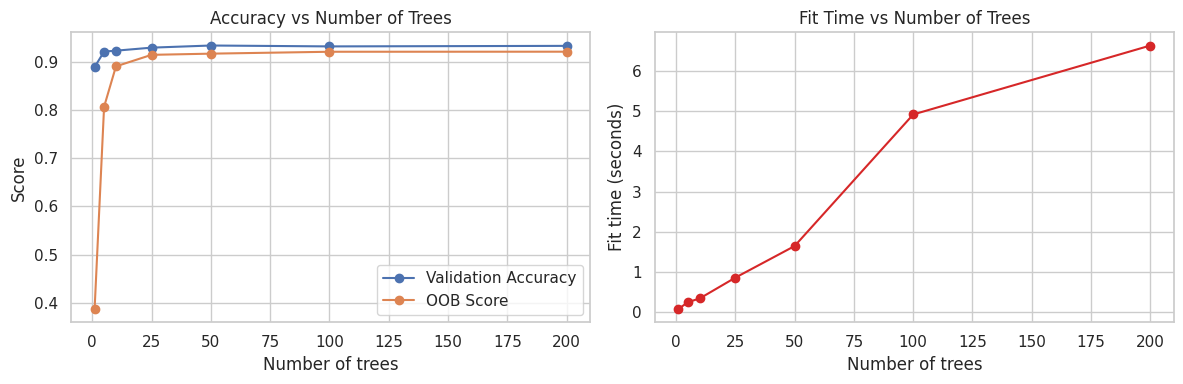

In [20]:
# TODO: Plot validation accuracy and OOB score against number of trees.
# TODO: Create a second plot for fit time against number of trees.

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Plot 1: validation accuracy and OOB score
axes[0].plot(n_trees_results["n_estimators"], n_trees_results["Validation Accuracy"], marker="o", label="Validation Accuracy")
axes[0].plot(n_trees_results["n_estimators"], n_trees_results["OOB Score"], marker="o", label="OOB Score")
axes[0].set_xlabel("Number of trees")
axes[0].set_ylabel("Score")
axes[0].set_title("Accuracy vs Number of Trees")
axes[0].legend()

# Plot 2: fit time
axes[1].plot(n_trees_results["n_estimators"], n_trees_results["Fit Time (s)"], marker="o", color="tab:red")
axes[1].set_xlabel("Number of trees")
axes[1].set_ylabel("Fit time (seconds)")
axes[1].set_title("Fit Time vs Number of Trees")

plt.tight_layout()
plt.show()

### Question 8

1. Around what number of trees did validation performance begin to stabilize?
2. How reliable was the OOB score for very small forests?
3. What is the cost of continuing to add trees after performance stabilizes?

**Your answer:**

- Ans 1 - Validation performance started stabilizing at about 25 to 50 trees. Validation accuracy was 0.929 with 25 trees and 0.934 with 50 trees. After that, it stayed around 0.932 to 0.933, and macro F1 stayed around 0.943.

- Ans 2 - The OOB score was not reliable for very small forests. The OOB score became stable and close to validation accuracy only after about 25 to 50 trees.

- Ans 3 - More trees after this point only cost more time and memory. Fit time increased from 4.1 seconds (100 trees) to 9.4 seconds (200 trees), but accuracy did not improve.

## 12. Experiment 5: Number of Features Considered per Split

Compare:

```python
[1.0, "sqrt", "log2", 0.5]
```

Use the same selected number of trees in every run.

- `1.0`: consider all features at each split;
- `"sqrt"`: consider approximately the square root of the feature count;
- `"log2"`: consider approximately the base-2 logarithm of the feature count;
- `0.5`: consider half of the features.

### Before running the experiment

What might happen to tree diversity when every split can consider all features?


- **Ans** - If every split can look at all features, the trees will look very similar. With fewer features per split, the trees become more different from each other.

In [21]:
feature_options = [1.0, "sqrt", "log2", 0.5]
selected_n_estimators = 50  # TODO: Replace using Experiment 4.

# TODO: Train one Random Forest for every max_features option.
# TODO: Store train accuracy, validation accuracy, validation macro F1,
# OOB score, and fit time in max_features_results.

rows = []
for option in feature_options:
    rf = RandomForestClassifier(
        n_estimators=selected_n_estimators,
        max_features=option,
        oob_score=True,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    )
    fitted, m = fit_and_measure(rf, X_train, y_train, X_val, y_val)
    rows.append({
        "max_features": option,
        "Features per split": fitted.n_features_in_ if option == 1.0 else (
            int(np.sqrt(fitted.n_features_in_)) if option == "sqrt" else
            int(np.log2(fitted.n_features_in_)) if option == "log2" else
            int(0.5 * fitted.n_features_in_)
        ),
        "Train Accuracy": m["Train Accuracy"],
        "Validation Accuracy": m["Validation Accuracy"],
        "Validation Macro F1": m["Validation Macro F1"],
        "OOB Score": fitted.oob_score_,
        "Fit Time (s)": m["Fit Time (s)"],
    })

max_features_results = pd.DataFrame(rows)
max_features_results

,max_features,Features per split,Train Accuracy,Validation Accuracy,Validation Macro F1,OOB Score,Fit Time (s)
0,1.0,16,0.999631,0.928387,0.940556,0.919508,11.454372
1,sqrt,4,0.999631,0.933555,0.944328,0.916677,2.356868
2,log2,4,0.999631,0.933555,0.944328,0.916677,2.458580
3,0.5,8,0.999754,0.934293,0.945040,0.918031,3.089549


### Question 9

1. Which setting produced the strongest validation macro F1?
2. Did using all features at every split necessarily produce the best forest?
3. Explain how random feature sampling can make trees less correlated.

**Your answer:**

- Ans 1 - max_features=0.5 (8 features per split) gave the strongest validation macro F1, 0.9450.

- Ans 2 - No. Using all 16 features gave the lowest validation macro F1 (0.9405), and it was also the slowest.

- Ans 3 - In a Random Forest, each split can see only a random part of the features. A strong feature is not available at every split, so trees must use other features too. This makes the trees different from each other and less correlated. When many different trees vote, their errors cancel each other, and the forest gets better. If all trees can see all features, they make similar splits and similar mistakes.


## 13. Experiment 6: Decision Tree and Random Forest Feature Importance

For a fitted tree-based model, `feature_importances_` measures the normalized total impurity reduction attributed to each feature.

This importance is model-specific. It does not establish causality, and correlated features may share or redistribute importance.

Use your selected Decision Tree and Random Forest settings. Compare their ten most important features.

Then use the Random Forest ranking to train forests with:

- the top 5 features;
- the top 10 features;
- all 16 features.

Do all comparisons on the validation set. Do not use the test set.

### Before running the experiment

Do you expect one Decision Tree and an ensemble of trees to produce identical importance rankings? Why?


- **Ans** - No, the rankings will not be identical. One tree is built on one dataset, so its importance depends on a few early splits. A forest uses many trees, each with different data and different features. So its importance is spread more evenly and is more stable. The top features may be similar, but the order and the values will differ.

In [22]:
# TODO: Create and fit your selected Decision Tree and selected Random Forest.
# TODO: Build one importance DataFrame for each model.
# Each table should contain Feature and Importance columns, sorted descending.

# Selected Decision Tree (Experiments 1-3)
final_tree = DecisionTreeClassifier(
    max_depth=10,
    min_samples_leaf=10,
    criterion="entropy",
    random_state=RANDOM_STATE,
)
final_tree.fit(X_train, y_train)

# Selected Random Forest (Experiments 4-5)
final_rf = RandomForestClassifier(
    n_estimators=50,
    max_features="sqrt",
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
final_rf.fit(X_train, y_train)

tree_importance = (
    pd.DataFrame({"Feature": X_train.columns, "Importance": final_tree.feature_importances_})
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)
rf_importance = (
    pd.DataFrame({"Feature": X_train.columns, "Importance": final_rf.feature_importances_})
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

print("Decision Tree - top 10")
display(tree_importance.head(10))
print("Random Forest - top 10")
display(rf_importance.head(10))

Decision Tree - top 10


,Feature,Importance
0,MajorAxisLength,0.320280
1,ShapeFactor1,0.200600
2,MinorAxisLength,0.145652
3,ShapeFactor3,0.130258
4,Roundness,0.047901
5,Perimeter,0.043509
6,Compactness,0.034780
7,ConvexArea,0.020742
8,ShapeFactor4,0.017608
9,ShapeFactor2,0.013046


Random Forest - top 10


,Feature,Importance
0,Perimeter,0.122339
1,Compactness,0.110446
2,ShapeFactor3,0.093816
3,MajorAxisLength,0.076868
4,MinorAxisLength,0.076268
5,ShapeFactor1,0.074752
6,AspectRatio,0.073342
7,ConvexArea,0.064014
8,Roundness,0.057374
9,EquivDiameter,0.054493


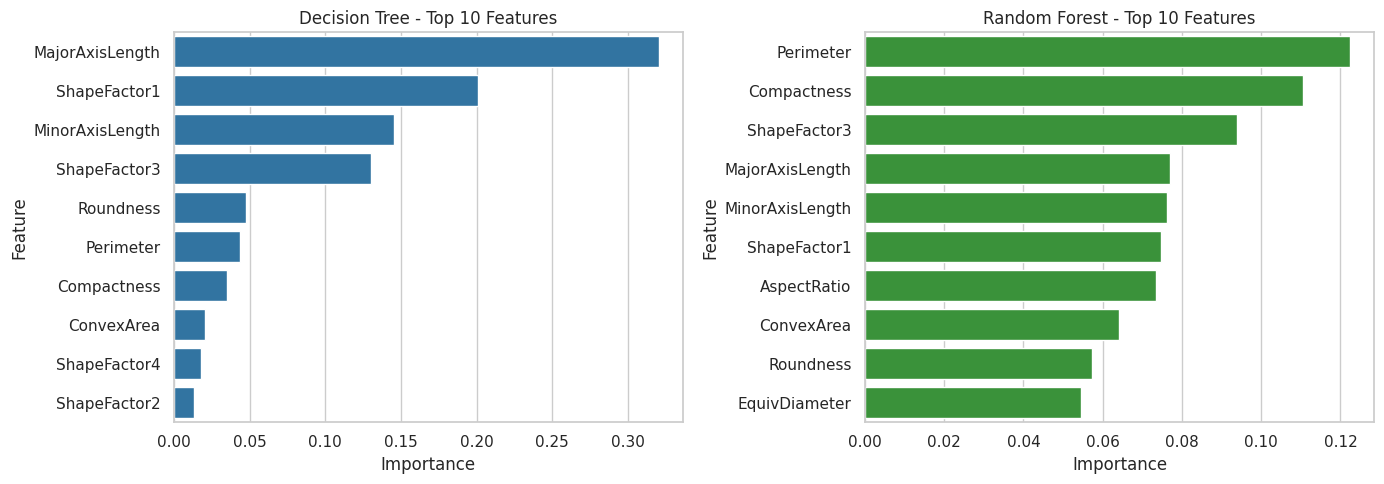

In [23]:
# TODO: Plot the top 10 features from each model side by side.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=tree_importance.head(10), x="Importance", y="Feature", ax=axes[0], color="tab:blue")
axes[0].set_title("Decision Tree - Top 10 Features")

sns.barplot(data=rf_importance.head(10), x="Importance", y="Feature", ax=axes[1], color="tab:green")
axes[1].set_title("Random Forest - Top 10 Features")

plt.tight_layout()
plt.show()

In [24]:
# TODO: Using the Random Forest ranking, evaluate forests trained with
# the top 5 features, top 10 features, and all features.
# Store feature count, selected feature names, validation accuracy,
# and validation macro F1 in reduced_feature_results.

rf_ranked_features = rf_importance["Feature"].tolist()
subset_sizes = [5, 10, 16]

rows = []
for k in subset_sizes:
    selected_features = rf_ranked_features[:k]
    rf = RandomForestClassifier(
        n_estimators=50,
        max_features="sqrt",
        n_jobs=-1,
        random_state=RANDOM_STATE,
    )
    rf.fit(X_train[selected_features], y_train)
    pred = rf.predict(X_val[selected_features])
    rows.append({
        "Feature Count": k,
        "Selected Features": selected_features,
        "Validation Accuracy": accuracy_score(y_val, pred),
        "Validation Macro F1": f1_score(y_val, pred, average="macro", zero_division=0),
    })

reduced_feature_results = pd.DataFrame(rows)
reduced_feature_results

,Feature Count,Selected Features,Validation Accuracy,Validation Macro F1
0,5,"[Perimeter, Compactness, ShapeFactor3, MajorAx...",0.905869,0.914081
1,10,"[Perimeter, Compactness, ShapeFactor3, MajorAx...",0.923588,0.932592
2,16,"[Perimeter, Compactness, ShapeFactor3, MajorAx...",0.931340,0.941651


### Question 10

1. Which features appeared near the top for both models?
2. Why can importance from one unrestricted tree be less stable than importance aggregated across a forest?
3. How much performance was retained using only the top 5 or top 10 features?
4. Does a low importance prove that a feature has no value in every possible model? Explain.

**Your answer:**

- Ans 1 - Both models have MajorAxisLength, ShapeFactor1, MinorAxisLength, ShapeFactor3, Roundness, Perimeter, Compactness and ConvexArea in their top 10. The size and shape features (axis lengths, perimeter, shape factors) matter most for both.

- Ans 2: One tree depends on its first few splits. If the training data changes a little, these splits can change, and the importance changes too. Also, when two features are similar, the tree may give the credit to only one of them. A forest uses many trees and averages their importance, so the result is more stable.

- Ans 3: The top 10 features kept about 99% of the performance. The top 5 features kept about 97%. So we lose only a little when we use fewer features. But the full 16 features gave the best validation score.

- Ans 4: No. Low importance only means the feature was not very useful in this model. A feature can have low importance if another correlated feature already gives the same information. For example, the model may use Perimeter and ignore a similar feature. If we remove Perimeter, the other feature can become important. A feature can also be useful only together with other features, or only for one small class. So importance depends on the model and the other features. It does not prove that a feature has no value.

## 14. Experiment Summary

Create a compact summary containing the most important result from every experiment.


In [25]:
# TODO: Complete this experiment summary.

def f1_at(df, col, value):
    # Validation Macro F1 of the row where `col` equals `value`
    return df.loc[df[col] == value, "Validation Macro F1"].iloc[0]

experiment_summary = pd.DataFrame([
    {
        "Experiment": "Maximum depth",
        "Selected setting": "max_depth=10",
        "Validation Macro F1": f1_at(depth_results, "max_depth", 10),
        "Observation": "Depth 1-3 underfits. Depth 10 is best. Unlimited depth (24) gets 100% train accuracy but lower validation.",
    },
    {
        "Experiment": "Minimum leaf size",
        "Selected setting": "min_samples_leaf=10",
        "Validation Macro F1": f1_at(leaf_results, "min_samples_leaf", 10),
        "Observation": "Larger leaves give a simpler tree (282 to 57 leaves). Middle values work best. The gain is very small.",
    },
    {
        "Experiment": "Split criterion",
        "Selected setting": "entropy",
        "Validation Macro F1": f1_at(criterion_results, "criterion", "entropy"),
        "Observation": "Entropy and log_loss gave the same tree. Gini was only about 0.002 lower. The difference is small.",
    },
    {
        "Experiment": "Number of trees",
        "Selected setting": "n_estimators=50",
        "Validation Macro F1": f1_at(n_trees_results, "n_estimators", 50),
        "Observation": "Big gain from 1 to 25 trees. Stable after 25-50 trees. More trees only cost more time.",
    },
    {
        "Experiment": "Features per split",
        "Selected setting": "max_features='sqrt'",
        "Validation Macro F1": f1_at(max_features_results, "max_features", "sqrt"),
        "Observation": "All 16 features was worst and slowest. sqrt and log2 gave the same result. 0.5 was only 0.0007 better.",
    },
    {
        "Experiment": "Feature subset",
        "Selected setting": "All 16 features",
        "Validation Macro F1": f1_at(reduced_feature_results, "Feature Count", 16),
        "Observation": "Top 10 kept about 99% of the performance and top 5 kept about 97%. All features gave the best score.",
    },
])

experiment_summary

,Experiment,Selected setting,Validation Macro F1,Observation
0,Maximum depth,max_depth=10,0.923272,Depth 1-3 underfits. Depth 10 is best. Unlimit...
1,Minimum leaf size,min_samples_leaf=10,0.922542,Larger leaves give a simpler tree (282 to 57 l...
2,Split criterion,entropy,0.924686,Entropy and log_loss gave the same tree. Gini ...
3,Number of trees,n_estimators=50,0.944328,Big gain from 1 to 25 trees. Stable after 25-5...
4,Features per split,max_features='sqrt',0.944328,All 16 features was worst and slowest. sqrt an...
5,Feature subset,All 16 features,0.941651,Top 10 kept about 99% of the performance and t...


## 15. Final Model Selection and Test Evaluation

Choose either a Decision Tree or Random Forest using only the validation evidence collected above.

Write down your final choice **before** evaluating the test set.

### Final choice

- Model: **Random Forest**
- Hyperparameters: **n_estimators=50, max_features="sqrt", random_state=42 (other settings at default)**
- Features used: **All 16 features**
- Validation evidence supporting this choice: **It had the best validation macro F1 (0.9443) and accuracy (0.9336). The best Decision Tree had macro F1 0.9247. Using all 16 features was better than the top 5 (0.9141) or top 10 (0.9326). More than 50 trees did not give any gain.**

In [26]:
# TODO: Combine the training and validation data.
# TODO: Recreate the selected model with the chosen hyperparameters.
# TODO: Fit it on the combined training + validation data.
# TODO: Predict the untouched test set exactly once.

# Combine training and validation data
X_final_train = pd.concat([X_train, X_val])
y_final_train = pd.concat([y_train, y_val])

# Recreate the selected model and fit it on train + validation
final_model = RandomForestClassifier(
    n_estimators=50,
    max_features="sqrt",
    n_jobs=-1,
    random_state=RANDOM_STATE,
)
final_model.fit(X_final_train, y_final_train)

# Predict the test set ONCE
y_test_pred = final_model.predict(X_test)

Test metrics:
  Accuracy: 0.9169
  Macro Precision: 0.9296
  Macro Recall: 0.9273
  Macro F1: 0.9284

Classification report:
              precision    recall  f1-score   support

    BARBUNYA       0.90      0.90      0.90       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.93      0.92      0.93       326
    DERMASON       0.90      0.93      0.92       709
       HOROZ       0.96      0.95      0.96       372
       SEKER       0.93      0.95      0.94       406
        SIRA       0.87      0.84      0.85       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92      0.92      2709



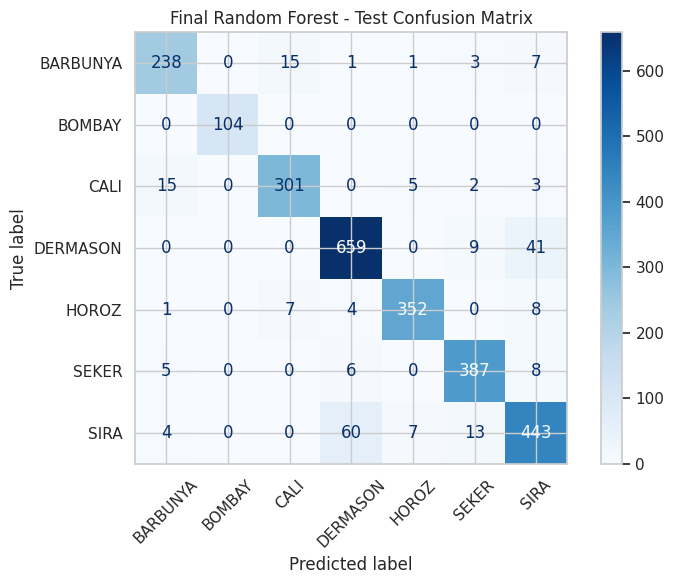

In [27]:
# TODO: Report test accuracy, macro precision, macro recall, and macro F1.
# TODO: Print the full classification report.
# TODO: Plot the confusion matrix.

test_metrics = classification_metrics(y_test, y_test_pred)
print("Test metrics:")
for name, value in test_metrics.items():
    print(f"  {name}: {value:.4f}")

print("\nClassification report:")
print(classification_report(y_test, y_test_pred, zero_division=0))

fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred, ax=ax, xticks_rotation=45, cmap="Blues"
)
ax.set_title("Final Random Forest - Test Confusion Matrix")
plt.tight_layout()
plt.show()

The final Random Forest works well on all 7 classes. Most errors happen between SIRA and DERMASON, and between BARBUNYA and CALI, because their shapes are similar. BOMBAY is classified perfectly.

## 16. Final Reflection

Answer briefly and in your own words.

### Question 11

Where did you observe underfitting? Where did you observe overfitting?

### Question 12

Why did the Random Forest generally behave differently from a single Decision Tree?

### Question 13

Which change had the largest effect on validation performance?

### Question 14

Did the final test result agree with the validation result? What would a large difference between them suggest?

### Question 15

If prediction speed or interpretability mattered more than a small accuracy improvement, could you choose a different final model? Explain.

**Your answers:**

- Ans 11 - **Underfitting**: A very shallow tree (max_depth 1 to 3) had low accuracy on both train and validation (for example, 0.41 at depth 1). Very large leaves (min_samples_leaf=50) also made the tree too simple. **Overfitting**: The unrestricted tree had 100% train accuracy but only about 89% validation accuracy. The baseline Random Forest also had 100% train accuracy, with a smaller gap.

- Ans 12 - One tree learns every detail of the training data, including noise, so it overfits. A forest trains many different trees on different samples and features. Their errors are different, so voting cancels many of them. This gives a higher and more stable validation score.

- Ans 13 - Increasing the tree depth from 1 to 10 had the largest effect (validation accuracy from 0.41 to 0.91). Other settings changed the result only a little. The most useful change was moving from a single tree to a Random Forest.

- Ans 14 - Yes, they roughly agree. The test accuracy (0.917) and macro F1 (0.928) are about 0.016 lower than validation (0.934 and 0.944). A small drop is normal, because we chose the settings using the validation set. A large difference between test and validation would suggest overfitting to the validation set, a bad split, or data leakage.

- Ans 15 - Yes. A single Decision Tree with depth 10 is faster to train and predict. It is also easier to explain, because we can follow its rules. A forest of 50 trees is slower and harder to explain. The forest was only about 0.02 better in macro F1. If speed or explanation matters more, a small tree is a good choice.

## Submission Checklist

Submit the completed notebook with:

- all TODO cells completed;
- all code cells executed and outputs visible;
- train/validation/test class-distribution checks;
- baseline Decision Tree and Random Forest results;
- result tables and plots for all six experiments;
- Decision Tree and Random Forest feature-importance plots;
- the completed experiment summary;
- final test metrics, classification report, and confusion matrix;
- answers to all 15 questions;
- a short conclusion naming your final model and the evidence behind it.


# Conclusion

**Final model**: Random Forest with n_estimators=50, max_features="sqrt", and all 16 features.

**Evidence**:
- On validation data, it had the best macro F1 (0.944). The best Decision Tree had 0.925.
- The forest was more stable than a single tree, which overfit (100% train accuracy, about 89% validation accuracy).
- More than 50 trees gave no real gain, and using all features was better than using only the top 5 or top 10.
- On the test set (used once), it reached accuracy 0.917 and macro F1 0.928. This is close to the validation result, so the model generalizes well.

**Remaining weakness**: Most errors are between SIRA and DERMASON, and between BARBUNYA and CALI, because these beans have similar shapes. BOMBAY was classified perfectly.